# Ejercicio 06 — Autoencoder y VAE con Fashion-MNIST

**Curso:** INF-8239 Ciencia de Datos II · **Unidad 3** · LAB10

Este notebook **no vuelve a entrenar**: lee lo que produjo `scripts/train_ae_vae.py` (carpeta `reports/`) y lo presenta con tablas y figuras.

**Pregunta:** reconstruir bien una imagen, ¿significa saber generar imágenes nuevas? ¿Qué cambia entre un autoencoder (AE), un autoencoder variacional (VAE) y una línea base lineal (PCA)?

> Nota de uso de IA: los textos interpretativos de este notebook fueron redactados con asistencia de IA a partir de los resultados reales de mi corrida. Están revisados contra las tablas y figuras; la declaración completa está en `AI_USE_DECLARATION.md`.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

REPORTS = next(p for p in (Path("reports"), Path("../reports")) if p.exists())
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
run = json.loads((REPORTS / "lab10_metrics.json").read_text(encoding="utf-8"))
models = run["models"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print("Leyendo resultados desde:", REPORTS.resolve())

Leyendo resultados desde: C:\Users\PC\Downloads\INF8239_U03_Generativos_Proyecto_Base_uv\INF8239_U03_Generativos_Proyecto_Base\reports


## 1. Datos, configuración y entorno
Fashion-MNIST (Zalando Research, licencia MIT): 60,000 imágenes de entrenamiento y 10,000 de prueba, de 28×28 píxeles en grises, normalizadas a [0, 1]. La prueba se reserva para la evaluación final. El dataset se descarga con Keras y **no se guarda en el repositorio**.

In [ ]:
print("Argumentos:", run["arguments"])
print("Entorno:", run["environment"])
print("Datos:", {k: v for k, v in run["data"].items() if k != "panel_indices"})
print("Índices del panel (fijados por semilla, no elegidos a mano):", run["data"]["panel_indices"])

Argumentos: {'epochs_ae': 6, 'epochs_vae': 8, 'limit': 0, 'seed': 42, 'latents': [2, 16], 'samples': 1000, 'panel_size': 16, 'quick': False}
Entorno: {'python': '3.12.14', 'os': 'Windows-11-10.0.26300-SP0', 'processor': 'Intel64 Family 6 Model 122 Stepping 8, GenuineIntel', 'tensorflow': '2.21.0', 'numpy': '2.5.3', 'gpu': []}
Datos: {'train_images': 60000, 'test_images': 10000, 'license': 'Fashion-MNIST, MIT', 'interpolation_pair': {'a': 892, 'b': 7743, 'classes': ['Ankle boot', 'Dress']}}
Índices del panel (fijados por semilla, no elegidos a mano): [858, 891, 941, 2013, 4325, 4383, 5262, 6537, 6968, 7174, 7355, 7609, 7728, 7860, 8577, 9752]


## 2. Reconstrucción
Se mide el error cuadrático medio (MSE, menor es mejor) y el PSNR (mayor es mejor) sobre las 10,000 imágenes de prueba. **PCA** es una línea base lineal: sirve para saber si los modelos neuronales realmente aportan algo.

,modelo,tipo,dim. latente,MSE,PSNR (dB)
0,AE-2,autoencoder,2,0.0585,12.3303
1,VAE-2,vae,2,0.0330,14.8159
2,PCA-2,pca,2,0.0456,13.4061
3,AE-16,autoencoder,16,0.0203,16.9264
4,VAE-16,vae,16,0.0165,17.8155
5,PCA-16,pca,16,0.0198,17.0284


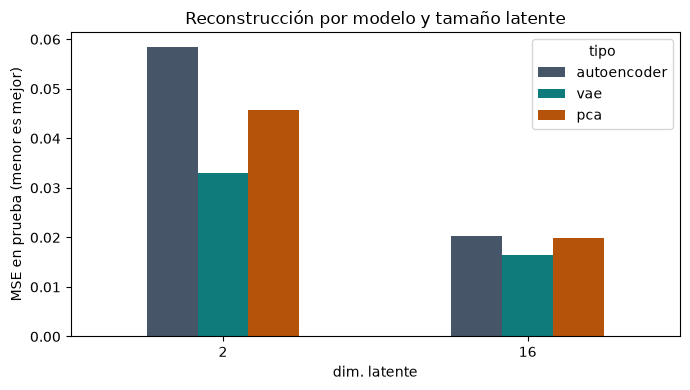

In [ ]:
rows = []
for name, m in models.items():
    rows.append({"modelo": name, "tipo": m["kind"], "dim. latente": m["latent_dim"], "MSE": m["recon_mse"],
                 "PSNR (dB)": m["recon_psnr_db"]})
recon = pd.DataFrame(rows)
display(recon.round(4))

pivot = recon.pivot(index="dim. latente", columns="tipo", values="MSE")[["autoencoder", "vae", "pca"]]
ax = pivot.plot(kind="bar", figsize=(7, 4), rot=0, color=["#475569", "#0f7c7b", "#b45309"])
ax.set_ylabel("MSE en prueba (menor es mejor)")
ax.set_title("Reconstrucción por modelo y tamaño latente")
plt.tight_layout()
plt.show()

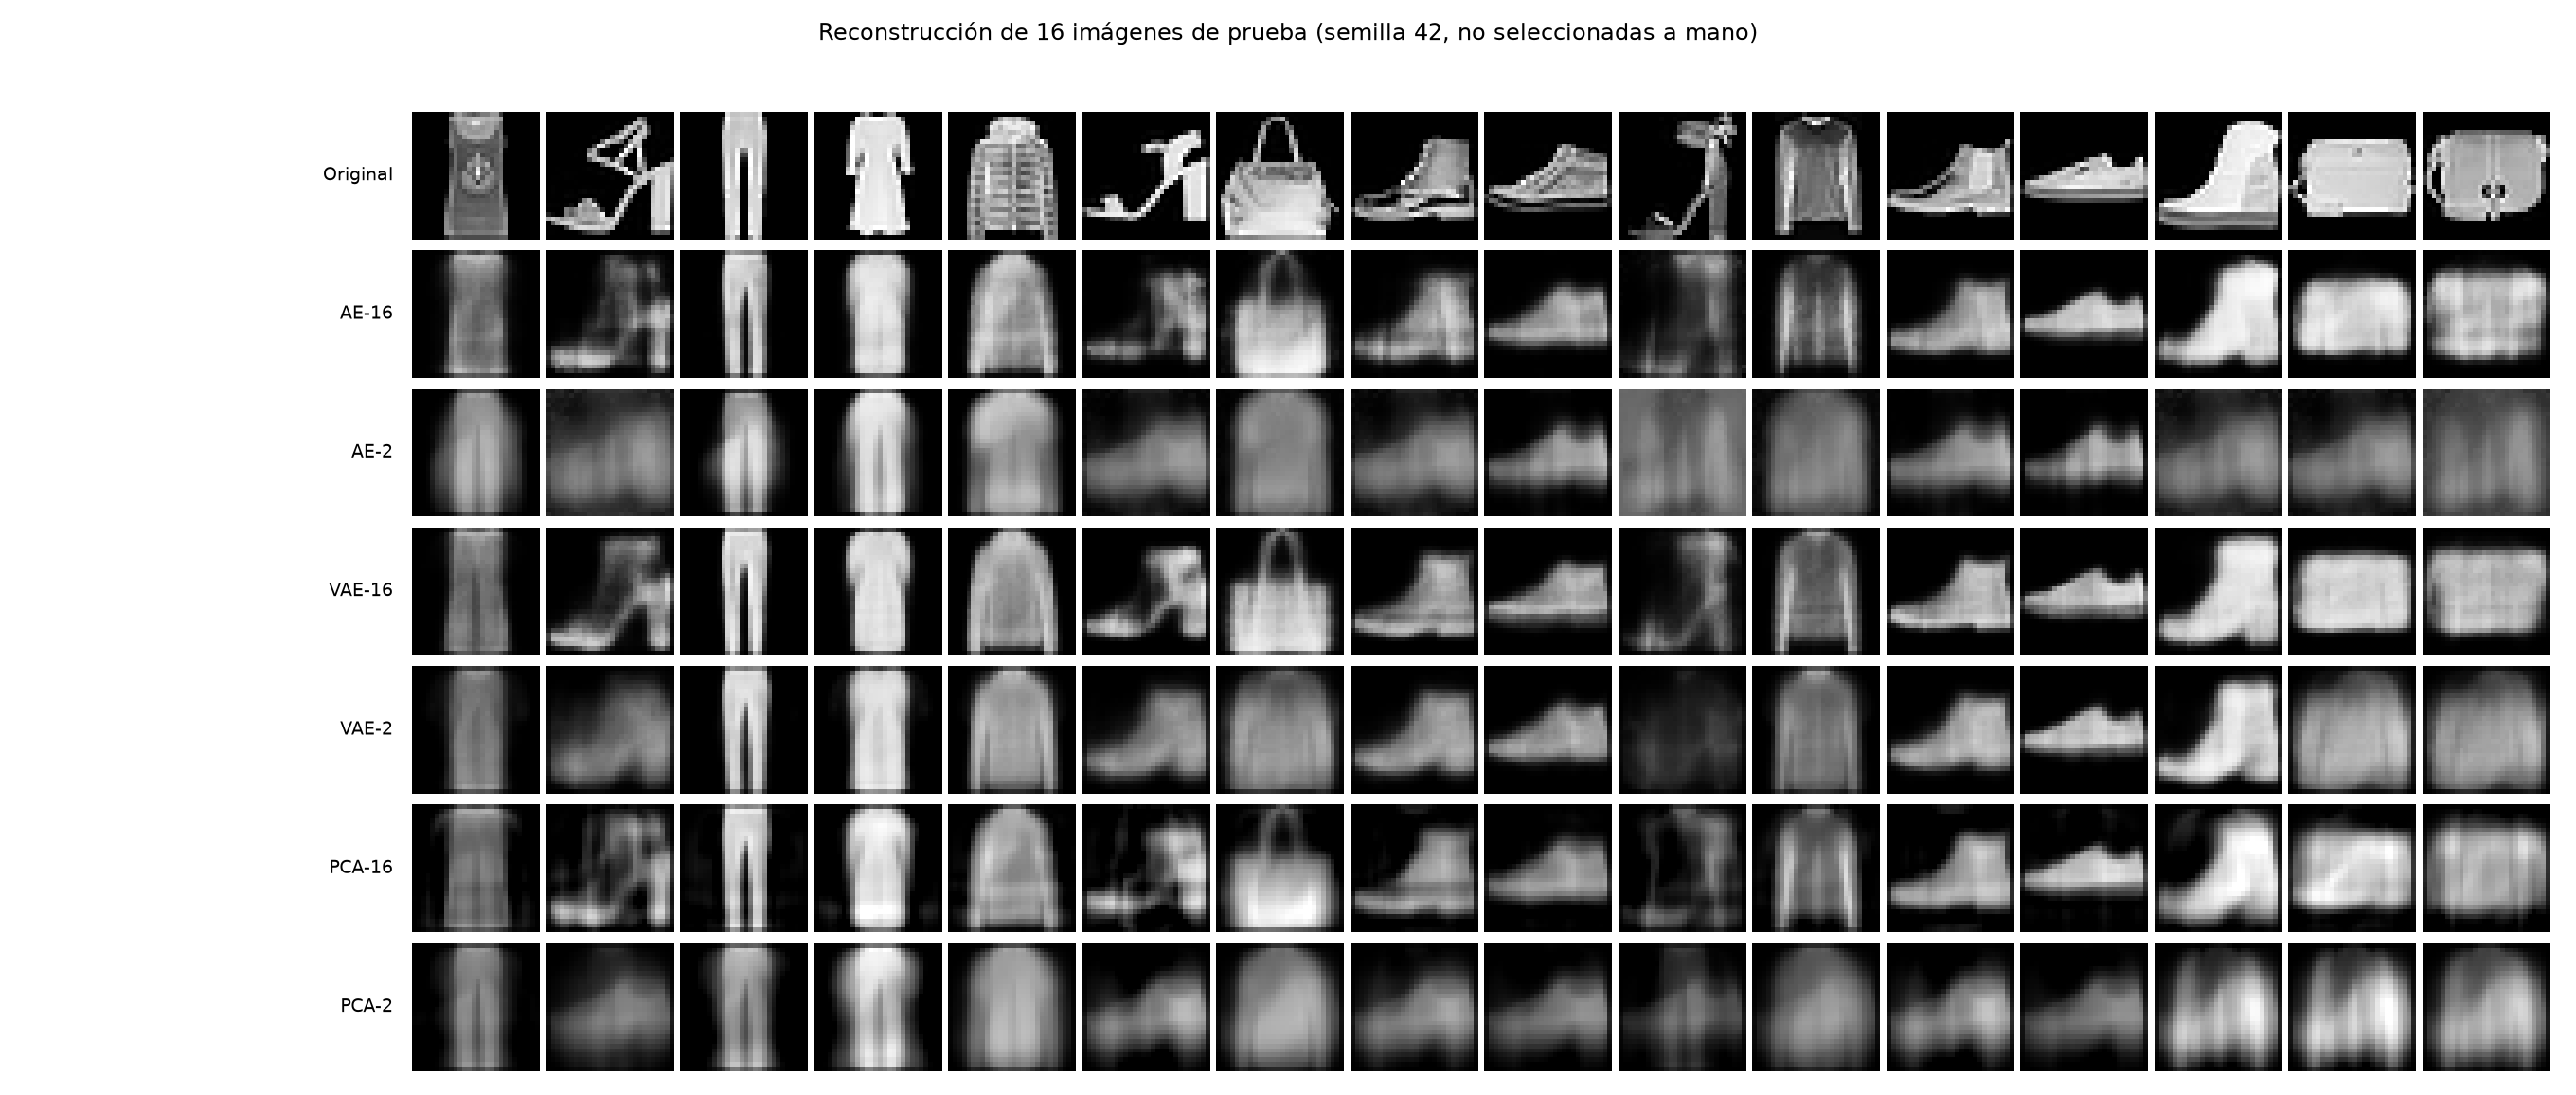

In [ ]:
display(Image(filename=str(REPORTS / "panel_reconstruction.png")))

**Observación y evidencia.** El VAE obtiene el menor error con 2 y con 16 dimensiones (0.033 y 0.0165). El AE de 16 dimensiones queda casi igual que PCA de 16 (0.0203 frente a 0.0198), y el AE de 2 dimensiones queda **peor que PCA de 2** (0.0585 frente a 0.0456).

**Interpretación.** Dos advertencias evitan una conclusión apresurada:
- La comparación AE–VAE **no es de igual capacidad**: el AE base tiene una sola capa lineal-sigmoide, mientras que el VAE tiene una capa oculta de 128 unidades (unos 200 mil parámetros frente a 4 mil con 2 dimensiones). La ventaja del VAE puede venir de esa arquitectura más grande y no de ser variacional.
- Las curvas (sección 3) muestran que el AE **seguía mejorando al terminar las 6 épocas**, así que su resultado es el de un modelo sin converger; con más entrenamiento podría acercarse a PCA.
Solo se entrenó con una semilla, por lo que diferencias pequeñas (como AE-16 frente a PCA-16) no se interpretan.

## 3. Curvas de entrenamiento y espacio latente

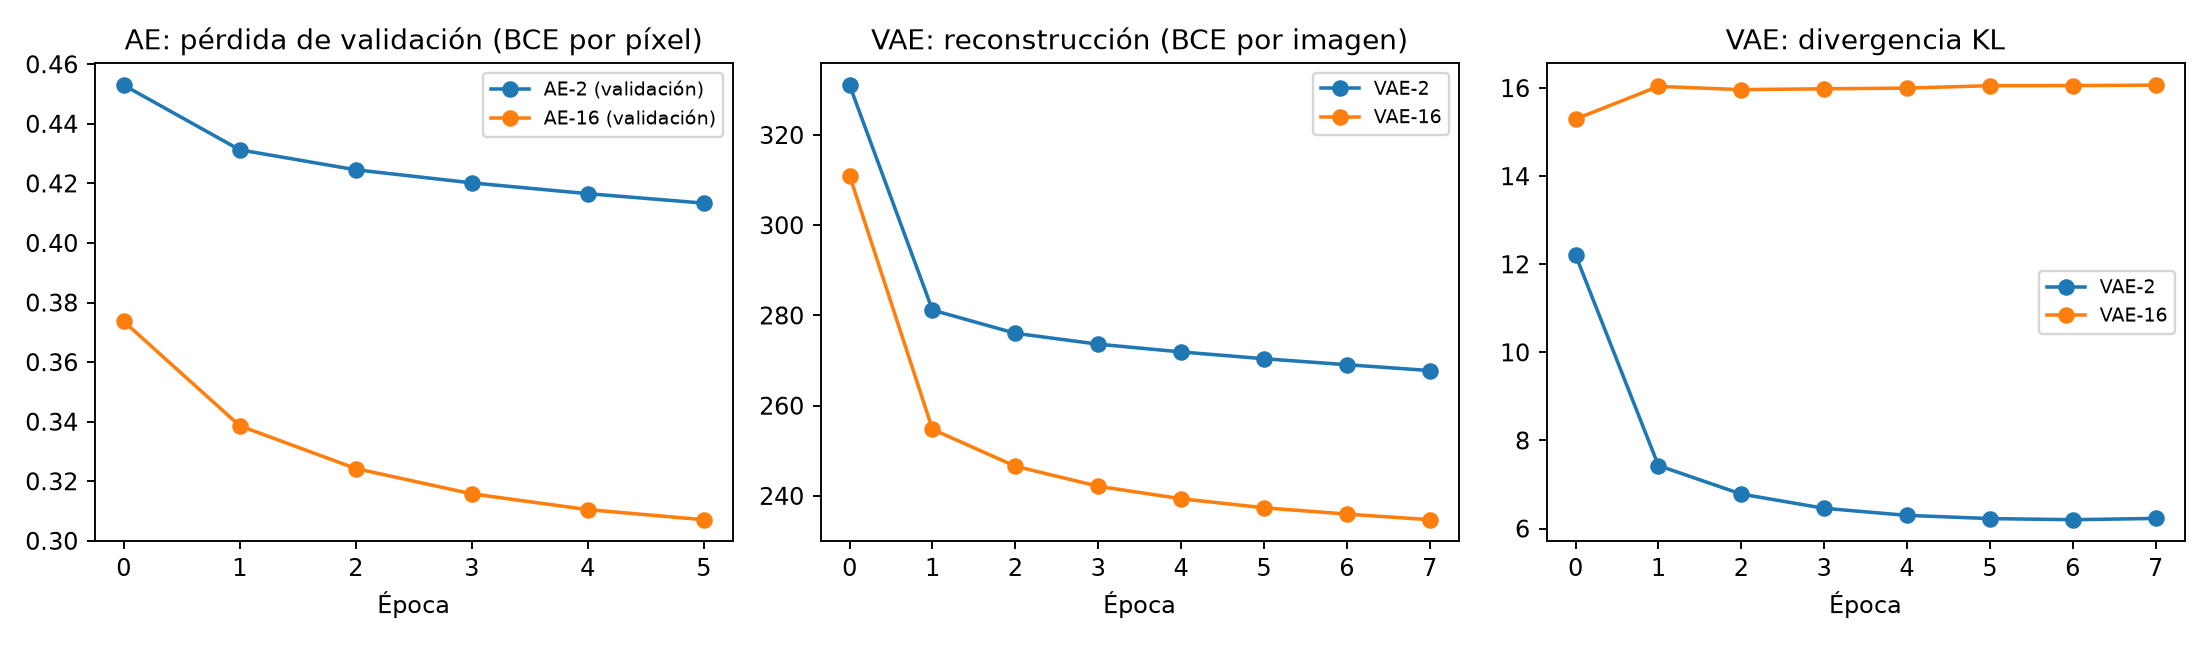

,modelo,pérdida de reconstrucción final,KL final
0,VAE-2,267.789,6.230
1,VAE-16,234.719,16.066


In [ ]:
display(Image(filename=str(REPORTS / "training_curves.png")))
vae_rows = [{"modelo": n, "pérdida de reconstrucción final": m["final_reconstruction_loss"], "KL final": m["final_kl"]}
            for n, m in models.items() if m["kind"] == "vae"]
display(pd.DataFrame(vae_rows).round(3))

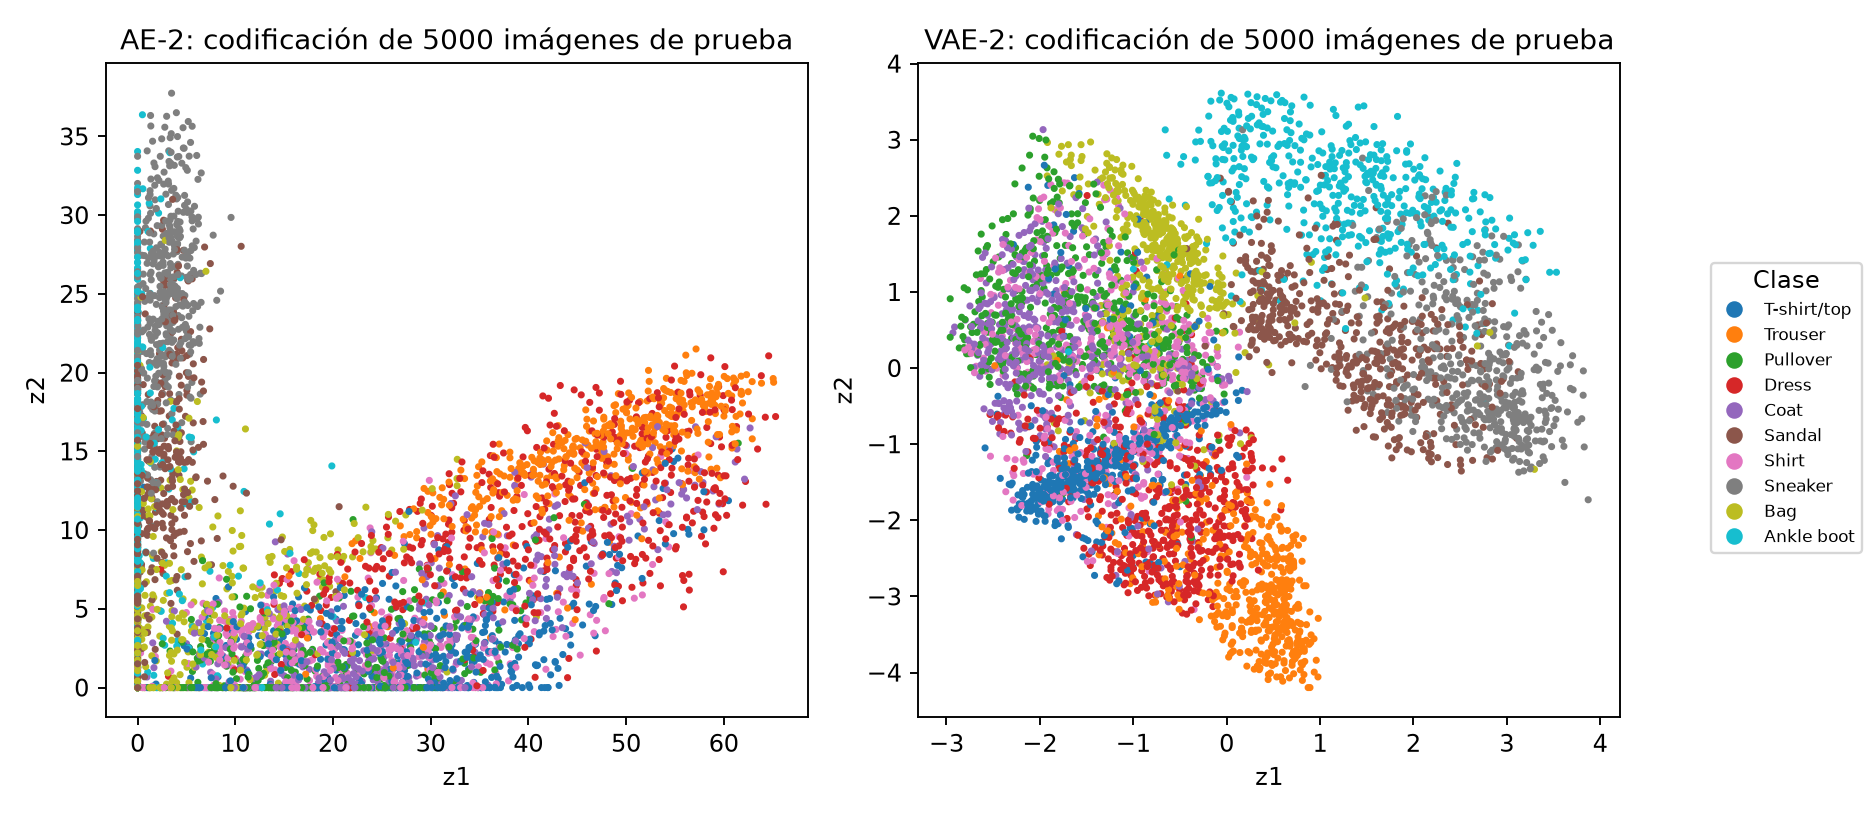

In [ ]:
display(Image(filename=str(REPORTS / "latent_space_2d.png")))

**Observación.** En el VAE, la divergencia KL se estabiliza en unos 6.2 (2 dimensiones) y 16.1 (16 dimensiones): el modelo usa más información del espacio latente cuanto mayor es su tamaño. En el espacio de 2 dimensiones, el AE concentra los puntos en el primer cuadrante, muchos pegados a los ejes (valores 0 por la activación ReLU) y con escalas de hasta 60. El VAE los agrupa alrededor del origen (entre −3 y 4) y ordena por tipo de prenda: pantalones abajo, botas arriba a la derecha, tenis y sandalias a la derecha; camisetas, camisas, suéteres y abrigos se **superponen** a la izquierda.

**Interpretación.** El KL empuja al VAE a ocupar la región que luego se muestrea, y el AE no tiene esa restricción. Que prendas parecidas se mezclen en el centro explica por qué esas clases son las más difíciles de generar y reconstruir con 2 dimensiones.

## 4. Generación desde ruido
Se decodifican 1,000 vectores z ~ N(0, I) (los mismos para AE y VAE del mismo tamaño). Para medir calidad sin juzgar a ojo se usa un clasificador pequeño como **regla de medir** (no es un modelo evaluado): reconoce Fashion-MNIST con exactitud 0.854 en imágenes reales.

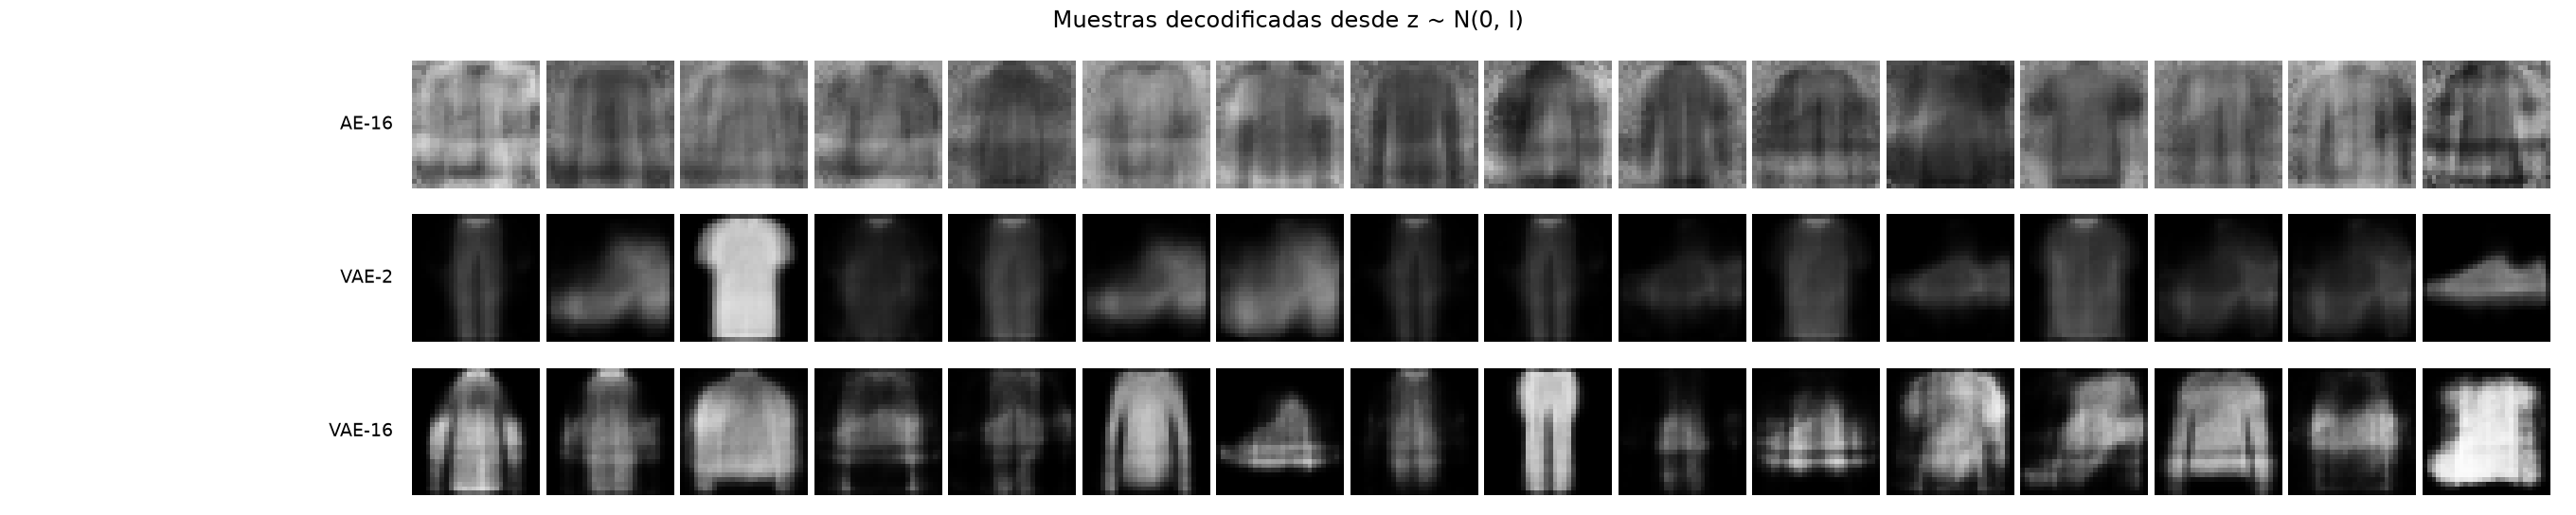

,modelo,dist. mediana al vecino,muestras muy cercanas (%),diversidad / real,clases presentes,entropía de clases,confianza media
0,imágenes reales (referencia),3.403,5.0,1.000,10,2.283,0.854
1,AE-2,5.675,0.0,0.166,1,-0.000,0.998
2,VAE-2,2.607,13.7,0.538,9,2.108,0.529
3,AE-16,6.320,0.0,0.465,2,0.008,0.975
4,VAE-16,3.767,0.1,0.681,10,2.229,0.653


La entropía máxima posible con 10 clases es 2.303


In [ ]:
display(Image(filename=str(REPORTS / "panel_samples.png")))
ref = run["real_images_reference"]
rows = [{"modelo": "imágenes reales (referencia)", "dist. mediana al vecino": ref["nn_distance_median"],
         "muestras muy cercanas (%)": 5.0, "diversidad / real": 1.0, "clases presentes": 10,
         "entropía de clases": ref["class_entropy_nats"], "confianza media": ref["mean_confidence"]}]
for name, m in models.items():
    s = m["sampling"]
    if s:
        rows.append({"modelo": name, "dist. mediana al vecino": s["nn_distance_median"],
                     "muestras muy cercanas (%)": 100 * s["share_closer_than_real_p05"],
                     "diversidad / real": s["diversity_ratio_vs_real"], "clases presentes": s["classes_present"],
                     "entropía de clases": s["class_entropy_nats"], "confianza media": s["mean_confidence"]})
display(pd.DataFrame(rows).round(3))
print("La entropía máxima posible con 10 clases es", round(float(np.log(10)), 3))

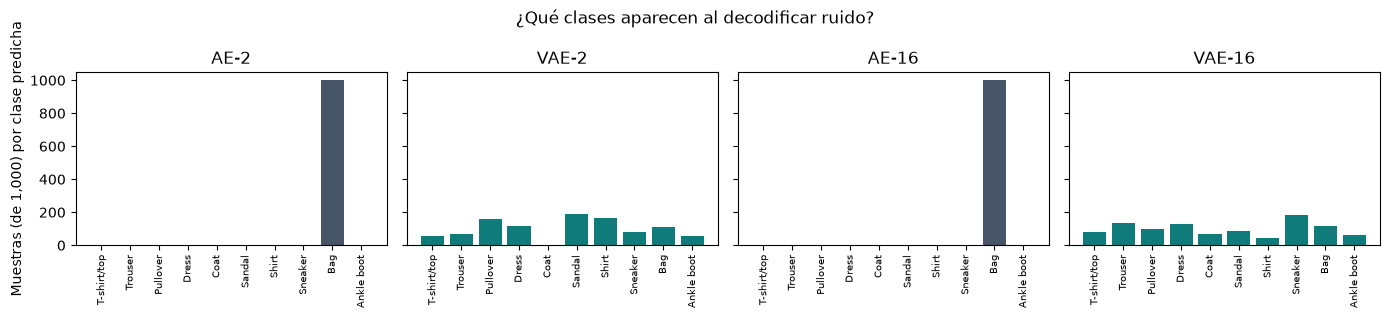

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for axis, name in zip(axes, ["AE-2", "VAE-2", "AE-16", "VAE-16"]):
    axis.bar(range(10), models[name]["sampling"]["class_counts"], color="#0f7c7b" if name.startswith("VAE") else "#475569")
    axis.set_title(name)
    axis.set_xticks(range(10))
    axis.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
axes[0].set_ylabel("Muestras (de 1,000) por clase predicha")
fig.suptitle("¿Qué clases aparecen al decodificar ruido?")
plt.tight_layout()
plt.show()

**Observación y evidencia.**
- **AE:** las 1,000 muestras de AE-2 y 999 de AE-16 se clasifican como **"Bag"** (bolso). Diversidad entre el 17 % y el 47 % de la real. El panel muestra la misma silueta gris con textura sucia una y otra vez.
- **VAE:** 9 de 10 clases con 2 dimensiones (falta "Coat") y las 10 con 16 dimensiones; diversidad del 54 % y 68 % de la real; entropía de clases de 2.11 y 2.23 (máximo 2.30).
- La confianza del clasificador en las muestras del VAE es baja (0.53 y 0.65 frente a 0.85 en imágenes reales): las imágenes son ambiguas o borrosas.

**Interpretación.** Reconstruir bien **no** implica generar bien. El AE no obliga al espacio latente a parecerse a una distribución muestreable, y al decodificar ruido (que incluye valores negativos que su capa ReLU nunca produjo) todo colapsa en un solo patrón. Ojo: el clasificador da **confianza muy alta (≈1.0) a esas muestras del AE**, aunque sean ruido. La confianza del clasificador no es una medida de calidad por sí sola. El VAE sí produce variedad, pero con poca nitidez.

## 5. Interpolación entre dos imágenes reales

Extremos: Ankle boot → Dress


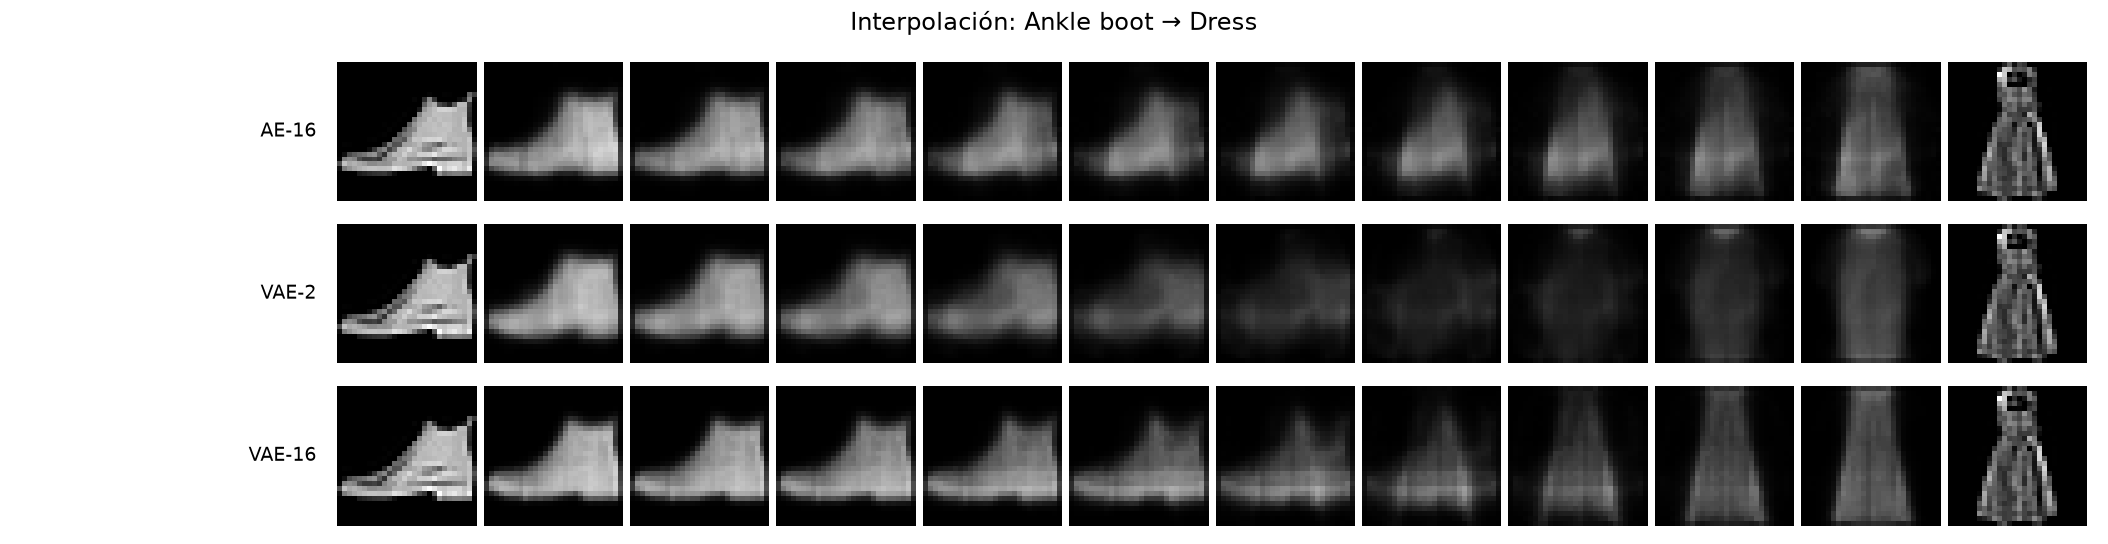

In [ ]:
pair = run["data"]["interpolation_pair"]
print("Extremos:", pair["classes"][0], "→", pair["classes"][1])
display(Image(filename=str(REPORTS / "interpolation.png")))

**Observación.** Las tres filas pasan de forma gradual de la bota al vestido. En VAE-2 la zona intermedia se vuelve **muy oscura** (pasa por una región con casi nada de contenido); en AE-16 y VAE-16 la transición es más continua. Las primeras y últimas columnas son las imágenes reales; las demás son decodificaciones.

**Interpretación.** Una transición suave indica que el espacio latente es continuo entre esos dos puntos, pero no garantiza que las imágenes intermedias sean prendas reales: son mezclas borrosas.

## 6. ¿Copia o variación? Vecino más cercano del entrenamiento

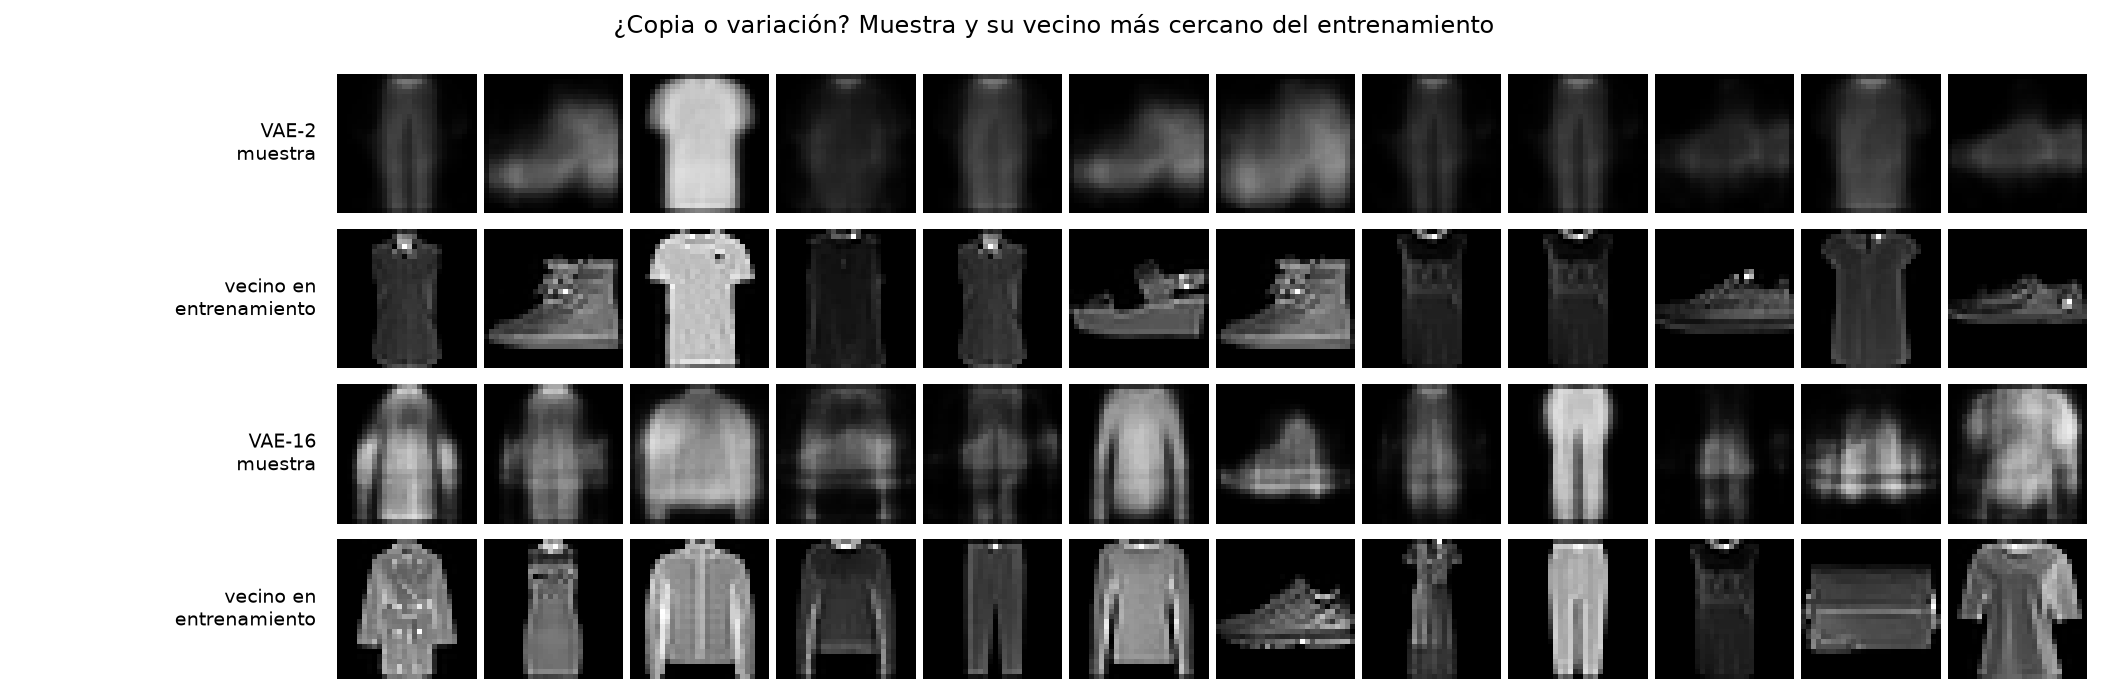

In [ ]:
display(Image(filename=str(REPORTS / "nearest_neighbors.png")))

**Observación.** Con VAE-16 solo el 0.1 % de las muestras queda más cerca de una imagen de entrenamiento que el 5 % más cercano de imágenes reales nuevas, y en el panel el vecino casi nunca es del mismo tipo que la muestra. Con VAE-2 la cifra sube al 13.7 %.

**Interpretación.** No hay evidencia de memorización en VAE-16. En VAE-2 la cifra alta **no prueba copia**: las muestras son manchas oscuras de bajo contraste, y la distancia euclídea entre dos imágenes oscuras es siempre pequeña. Es un **límite de la métrica**. Además, que una muestra no sea copia no prueba que sea original ni privada: el modelo aprendió de esas imágenes.

## 7. Costo computacional

In [ ]:
rows = []
for name, m in models.items():
    rows.append({"modelo": name, "entrenamiento (s)": m["train_seconds"], "parámetros": m["parameters"],
                 "memoria de parámetros (KB)": m["parameter_memory_kb"],
                 "decodificar (ms/imagen)": m.get("decode_ms_per_image")})
cost = pd.DataFrame(rows)
display(cost.round(3))
env = run["environment"]
print(f"Hardware: {env['processor']} · CPU (GPU: {env['gpu']}) · TensorFlow {env['tensorflow']}")

,modelo,entrenamiento (s),parámetros,memoria de parámetros (KB),decodificar (ms/imagen)
0,AE-2,31.836,3922,15.320,0.203
1,VAE-2,133.576,202516,791.078,0.357
2,PCA-2,9.595,2352,9.188,NaN
3,AE-16,43.988,25888,101.125,0.257
4,VAE-16,121.980,207920,812.188,0.234
5,PCA-16,7.391,13328,52.062,NaN


Hardware: Intel64 Family 6 Model 122 Stepping 8, GenuineIntel · CPU (GPU: []) · TensorFlow 2.21.0


**Interpretación.** PCA-16 entrena en 7 s y obtiene un error solo ≈20 % mayor que VAE-16 (122 s). El VAE tarda entre 3 y 4 veces más que el AE (122–134 s frente a 32–44 s) y tiene entre 8 veces (16 dimensiones) y 50 veces (2 dimensiones) más parámetros. Decodificar es barato (menos de 0.4 ms por imagen), por lo que la aplicación solo ejecuta inferencia y no entrena. Una ganancia de error pequeña se paga con un costo grande; para comprimir sin generar, PCA es una alternativa razonable.

## 8. Cierre interpretativo

| Pregunta | Respuesta |
|---|---|
| Resultado de reconstrucción | VAE-16 mejor (MSE 0.0165); AE-16 ≈ PCA-16; AE-2 peor que PCA-2 (sin converger). |
| Resultado de generación | El AE colapsa en un solo patrón; el VAE produce las 10 clases (16 dim.), pero borrosas. |
| Evidencia de diversidad | Diversidad 0.68 de la real y entropía 2.23/2.30 en VAE-16; 0.17–0.47 en AE. |
| Comportamiento del espacio latente | VAE: región acotada y ordenada por tipo; AE: puntos pegados a los ejes con escalas de hasta 60. |
| Costo computacional | VAE entre 3× y 4× el tiempo del AE; PCA ≈7–10 s; inferencia < 0.4 ms por imagen. |
| Riesgo o limitación | Una semilla; AE sin converger; arquitecturas de distinta capacidad; métrica de vecino sensible a imágenes oscuras; muestras borrosas. |
| Decisión sobre uso previsto | Usar el VAE-16 como demostración educativa de espacio latente y generación. **No** usarlo para producir imágenes que se presenten como reales, ni afirmar privacidad u originalidad. |

**Siguiente experimento:** entrenar más épocas y con tres semillas, igualar la capacidad del AE y del VAE, y probar un VAE convolucional para mejorar la nitidez.